# 02 — Multiple Linear Regression (MLR)


**Dataset:** `Practical_Dataset for ML.xlsx` (worksheet `Data`)  
**Target:** `price_etb`  
**Split:** 80% training / 20% test, `random_state=42`

## Learning objectives
- Use multiple predictors to estimate a continuous target.
- Interpret coefficients while recognizing limitations.
- Compare training and test performance.
- Inspect residuals and coefficient magnitudes.

## 1. Import libraries

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TARGET = "price_etb"

## 2. Load and inspect the dataset

In [2]:
possible_paths = [
    Path("data") / "Practical_Dataset for ML.xlsx",
    Path("ML_Course") / "data" / "Practical_Dataset for ML.xlsx",
    Path("..") / "data" / "Practical_Dataset for ML.xlsx",
    Path("Practical_Dataset for ML.xlsx"),
]
DATA_PATH = next((p for p in possible_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Workbook not found. Put 'Practical_Dataset for ML.xlsx' in the data/ folder "
        "or set DATA_PATH to its full path."
    )

df = pd.read_excel(DATA_PATH, sheet_name="Data")
print("Loaded:", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))

Loaded: ..\data\Practical_Dataset for ML.xlsx
Dataset shape: (3000, 17)


,house_id,size_sqm,num_bedrooms,num_bathrooms,floor_level,age_years,renovated,distance_to_bole_km,distance_to_main_road_m,has_garage,parking_spaces,has_garden,security_service,water_supply_hours_per_day,school_rating,days_on_market,price_etb
0,AA-10000,84.8,3,3,0,12,1,9.54,195,1,1,0,1,18.1,4.2,56,4664000
1,AA-10001,142.1,4,3,12,21,0,2.03,119,1,3,0,1,9.1,6.1,19,6209000
2,AA-10002,110.3,3,3,0,6,0,6.96,260,0,0,1,0,24.0,6.7,19,5804000
3,AA-10003,32.0,1,1,11,5,0,7.28,157,0,0,0,0,13.5,4.6,74,1134000
4,AA-10004,61.9,2,1,6,13,0,10.04,153,1,2,0,1,18.1,7.5,12,1810000


,dtype
house_id,str
size_sqm,float64
num_bedrooms,int64
num_bathrooms,int64
floor_level,int64
age_years,int64
renovated,int64
distance_to_bole_km,float64
distance_to_main_road_m,int64
has_garage,int64


## 3. Select multiple numeric features

The target and identifier `house_id` are excluded. This notebook uses numeric predictors to keep the workflow clear. Categorical variables need separate encoding.

In [3]:
if TARGET not in df.columns:
    raise KeyError(f"Target column {TARGET!r} not found. Available columns: {list(df.columns)}")

excluded = {TARGET, "house_id"}
numeric_features = df.select_dtypes(include=np.number).columns.tolist()
FEATURES = [c for c in numeric_features if c not in excluded]

if not FEATURES:
    raise ValueError("No numeric predictors found.")

X = df[FEATURES].copy()
y = pd.to_numeric(df[TARGET], errors="coerce")
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

print("Predictors:", FEATURES)
print("Rows with a valid target:", len(y))
print("Missing values in predictors before imputation:")
display(X.isna().sum().to_frame("missing_count"))

Predictors: ['size_sqm', 'num_bedrooms', 'num_bathrooms', 'floor_level', 'age_years', 'renovated', 'distance_to_bole_km', 'distance_to_main_road_m', 'has_garage', 'parking_spaces', 'has_garden', 'security_service', 'water_supply_hours_per_day', 'school_rating', 'days_on_market']
Rows with a valid target: 3000
Missing values in predictors before imputation:


,missing_count
size_sqm,0
num_bedrooms,0
num_bathrooms,0
floor_level,0
age_years,0
renovated,0
distance_to_bole_km,0
distance_to_main_road_m,0
has_garage,0
parking_spaces,0


## 4. Split the data and create a preprocessing/model pipeline

The median imputer is fitted on training data only. Use the same split and eligible features across all models for fair comparison.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

mlr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression()),
])

print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
mlr.fit(X_train, y_train)

Training rows: 2,400; test rows: 600


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['size_sqm','num_bedrooms','num_bathrooms',..., 'water_supply_hours_per_day','school_rating','days_on_market']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value""

## 5. Evaluate training and test performance

In [5]:
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

train_pred = mlr.predict(X_train)
test_pred = mlr.predict(X_test)

results = pd.DataFrame([
    {"Dataset": "Train", **metrics(y_train, train_pred)},
    {"Dataset": "Test", **metrics(y_test, test_pred)},
])
display(results.round(4))

,Dataset,MAE,MSE,RMSE,R2
0,Train,1.151729e+06,3.174719e+12,1.781774e+06,0.8648
1,Test,1.235494e+06,4.450912e+12,2.109718e+06,0.8336


## 6. Examine model coefficients

Each coefficient estimates the change in predicted target associated with a one-unit increase in that predictor, holding the other included predictors constant. Coefficients are not automatically causal effects and their sizes depend on feature units.

In [6]:
linear_model = mlr.named_steps["model"]
coef_table = pd.DataFrame({
    "Feature": FEATURES,
    "Coefficient": linear_model.coef_,
})
coef_table["Absolute_Coefficient"] = coef_table["Coefficient"].abs()
display(coef_table.sort_values("Absolute_Coefficient", ascending=False).round(4))
print(f"Intercept: {linear_model.intercept_:,.4f}")

,Feature,Coefficient,Absolute_Coefficient
5,renovated,564067.6022,564067.6022
11,security_service,306554.9927,306554.9927
6,distance_to_bole_km,-278239.2658,278239.2658
10,has_garden,231596.6737,231596.6737
9,parking_spaces,100806.5412,100806.5412
1,num_bedrooms,-59776.3905,59776.3905
4,age_years,-51220.6985,51220.6985
0,size_sqm,48021.0933,48021.0933
8,has_garage,40993.5092,40993.5092
3,floor_level,-11112.5030,11112.5030


Intercept: 1,730,867.2507


## 7. Actual vs predicted and residual plots

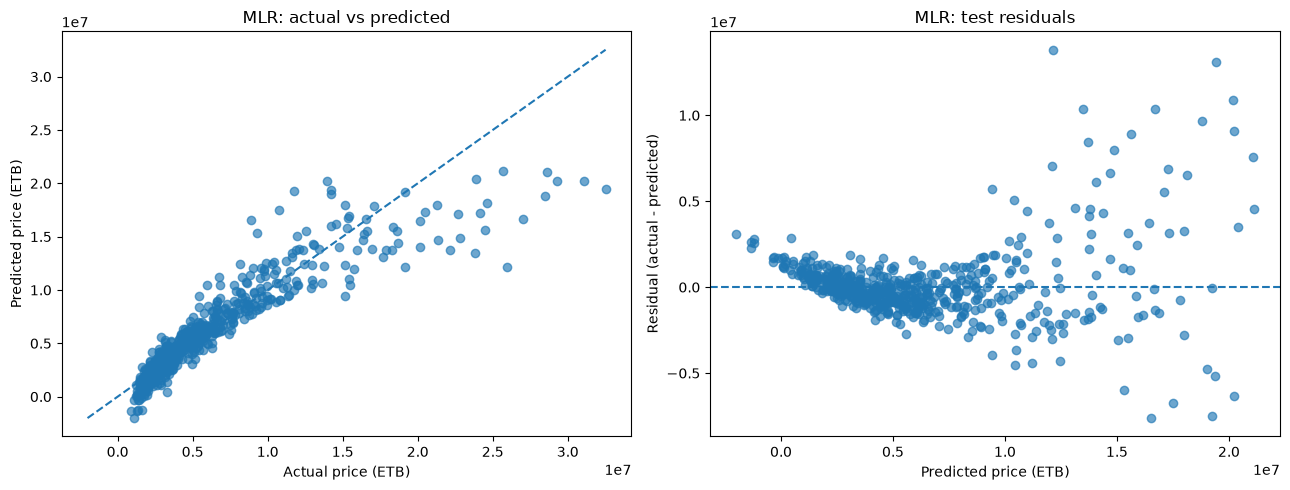

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, test_pred, alpha=0.65)
lo = min(float(y_test.min()), float(np.min(test_pred)))
hi = max(float(y_test.max()), float(np.max(test_pred)))
axes[0].plot([lo, hi], [lo, hi], linestyle="--")
axes[0].set_xlabel("Actual price (ETB)")
axes[0].set_ylabel("Predicted price (ETB)")
axes[0].set_title("MLR: actual vs predicted")

residuals = y_test.to_numpy() - np.asarray(test_pred)
axes[1].scatter(test_pred, residuals, alpha=0.65)
axes[1].axhline(0, linestyle="--")
axes[1].set_xlabel("Predicted price (ETB)")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("MLR: test residuals")

plt.tight_layout()
plt.show()

## 8. Compare against Simple Linear Regression

If Notebook 01 has already been run, load its saved metrics and compare test performance. If the file is not present, this cell explains how to compare manually.

In [8]:
slr_metrics_path = Path("outputs") / "metrics" / "01_slr_metrics.csv"
if slr_metrics_path.exists():
    slr_results = pd.read_csv(slr_metrics_path)
    print("Notebook 01 metrics:")
    display(slr_results)
    print("Compare the Test MAE/RMSE (lower is better) and Test R2 (generally higher is better).")
else:
    print("Run Notebook 01 first to save its metrics, then rerun this cell.")
    print("Compare the Test MAE/RMSE (lower is better) and Test R2 (generally higher is better).")

Notebook 01 metrics:


,Dataset,MAE,MSE,RMSE,R2
0,Train,1.485776e+06,5.263627e+12,2.294260e+06,0.775895
1,Test,1.603659e+06,6.987126e+12,2.643317e+06,0.738793


Compare the Test MAE/RMSE (lower is better) and Test R2 (generally higher is better).


## 9. Important feature-leakage warning

If the goal is to predict a property's price before it is listed, `days_on_market` may not be known at prediction time. Including information that would only become available later can inflate performance. Exclude it if it is unavailable at the real prediction moment, then rerun the notebook and compare.

In [9]:
if "days_on_market" in FEATURES:
    print("WARNING: 'days_on_market' is included. Check whether it is known at prediction time.")
else:
    print("'days_on_market' is not included in the current feature set.")

## 10. Save outputs

In [10]:
output_dir = Path("outputs") / "metrics"
output_dir.mkdir(parents=True, exist_ok=True)

results.to_csv(output_dir / "02_mlr_metrics.csv", index=False)
coef_table.to_csv(output_dir / "02_mlr_coefficients.csv", index=False)

print("Saved outputs to:", output_dir.resolve())

Saved outputs to: C:\Users\hp\ML_Course\Notebooks\outputs\metrics


## 11. What to explain 

- MLR estimates the target from several predictors using a linear combination of their values.
- The imputer handles missing predictor values using training-set medians.
- Coefficients are conditional on the other included predictors and their measurement units.
- Correlated predictors can make coefficients unstable even if overall predictions are reasonable.
- Use held-out test metrics to compare generalization; do not select models using test performance repeatedly.

### Understanding check
1. What is the difference between SLR and MLR?
2. How should you interpret a coefficient when other predictors are held constant?
3. What is multicollinearity, and why can it matter?
4. What is data leakage, and why might `days_on_market` be risky?